# Bank Account Fraud: exploratory analysis

What the BAF `Base.csv` data looks like, and which project decisions it supports. Every
section ends with a **Decision** paragraph naming the decision or ADR it backs.

The data is loaded through the project's own dataset-side Application module, so the
-1 sentinels and negative `intended_balcon_amount` are already missing values here,
exactly as the model sees them.

**Months 0–5 only**, except in section 5 (drift): the Test Months (6–7) are kept out of
every analysis that could shape a modelling choice. Only aggregates are shown, never
individual rows.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud_api.application import CATEGORIES, FIELDS, SENTINEL_FIELDS, read_dataset

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
dataset = read_dataset(ROOT / "data" / "Base.csv")
everything = dataset.applications.assign(fraud=dataset.labels, month=dataset.months)
months_0_5 = everything[everything["month"] <= 5]

# One look for every chart: the project's palette, recessive axes, no chart junk.
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#c9c8c2"
INK, INK_2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left",
    "axes.titlecolor": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "legend.frameon": False,
})


def percent_axis(ax, axis="y"):
    formatter = plt.FuncFormatter(lambda v, _: f"{v:.1%}" if v < 0.1 else f"{v:.0%}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)


def fraud_rate(frame, by):
    return frame.groupby(by, observed=True)["fraud"].agg(rate="mean", applications="size")


print(f"{len(months_0_5):,} Applications in Months 0–5, {len(FIELDS)} fields")

794,989 Applications in Months 0–5, 29 fields


## 1. Overview and fraud rate by Month

Fraudulent Applications: 8,151 of 794,989 (1.03%)


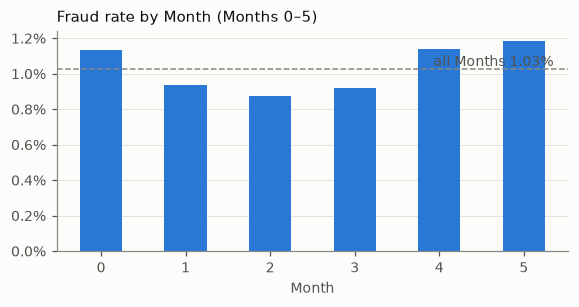

,rate,applications
month,,
0,1.13%,"132,440"
1,0.94%,"127,620"
2,0.87%,"136,979"
3,0.92%,"150,936"
4,1.14%,"127,691"
5,1.18%,"119,323"


In [2]:
overall = months_0_5["fraud"].mean()
by_month = fraud_rate(months_0_5, "month")
print(f"Fraudulent Applications: {months_0_5['fraud'].sum():,} of {len(months_0_5):,} ({overall:.2%})")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(by_month.index, by_month["rate"], width=0.5, color=BLUE)
ax.axhline(overall, color=MUTED, linewidth=1, linestyle="--")
ax.text(5.35, overall, f"all Months {overall:.2%}", va="bottom", ha="right", color=INK_2)
ax.set_title("Fraud rate by Month (Months 0–5)")
ax.set_xlabel("Month")
percent_axis(ax)
plt.show()
by_month.style.format({"rate": "{:.2%}", "applications": "{:,}"})

**Decision.** About one Application in a hundred is fraudulent, and the rate moves from
Month to Month. Accuracy would be 99% for a model that flags nothing, so the project
measures **Recall@5%FPR** (the share of fraud caught when 5% of Legitimate Applications
are sent to Review) and PR-AUC. Because the rate shifts over time, the data is split by
Month, never at random: train on Months 0–4, choose the Threshold on Month 5, test on
Months 6–7 (**ADR 0001**).

## 2. Missing values and their fraud signal

The dataset writes -1 for a missing value in five fields; negative
`intended_balcon_amount` is treated the same way (section 3).

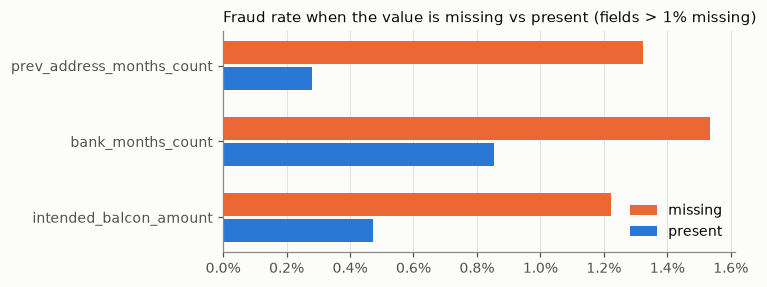

,share missing,fraud rate when missing,fraud rate when present
field,,,
prev_address_months_count,71.50%,1.32%,0.28%
current_address_months_count,0.38%,0.30%,1.03%
bank_months_count,25.10%,1.54%,0.85%
session_length_in_minutes,0.19%,0.86%,1.03%
device_distinct_emails_8w,0.04%,0.97%,1.03%
intended_balcon_amount,73.70%,1.22%,0.47%


In [3]:
rows = []
for field in [*SENTINEL_FIELDS, "intended_balcon_amount"]:
    missing = months_0_5[field].isna()
    rows.append({
        "field": field,
        "share missing": missing.mean(),
        "fraud rate when missing": months_0_5.loc[missing, "fraud"].mean(),
        "fraud rate when present": months_0_5.loc[~missing, "fraud"].mean(),
    })
missingness = pd.DataFrame(rows).set_index("field")

shown = missingness[missingness["share missing"] > 0.01]
fig, ax = plt.subplots(figsize=(6, 2.6))
y = np.arange(len(shown))
ax.barh(y - 0.17, shown["fraud rate when missing"], height=0.3, color=ORANGE, label="missing")
ax.barh(y + 0.17, shown["fraud rate when present"], height=0.3, color=BLUE, label="present")
ax.set_yticks(y, shown.index)
ax.invert_yaxis()
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
percent_axis(ax, "x")
ax.set_title("Fraud rate when the value is missing vs present (fields > 1% missing)")
ax.legend(loc="lower right")
plt.show()
missingness.style.format("{:.2%}")

**Decision.** Missingness is informative: Applicants without a previous address are
fraudulent several times as often as those with one, and a missing bank-months count
nearly doubles the rate. So missing values are **kept as missing**, never imputed away
for LightGBM, which learns its own direction for them; the logistic-regression baseline
gets explicit **missing-value indicators** next to its median imputation. The API
accepts `null` in exactly these six fields.

## 3. Privacy artefacts

The BAF authors protected Applicants' privacy by coarsening some fields and adding noise
to others. This section reads the raw file directly, since the Application module has
already converted the negative amounts.

income values: [np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8), np.float64(0.9)]
customer_age values: [np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70), np.int64(80), np.int64(90)]
proposed_credit_limit values: [np.int64(190), np.int64(200), np.int64(210), np.int64(490), np.int64(500), np.int64(510), np.int64(990), np.int64(1000), np.int64(1500), np.int64(1900), np.int64(2000), np.int64(2100)]
negative intended_balcon_amount: 73.7% of Applications, median -1.01


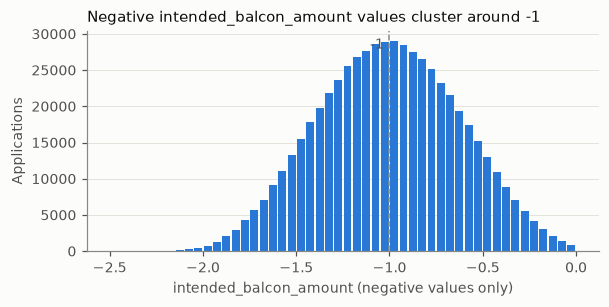

In [4]:
raw = pd.read_csv(ROOT / "data" / "Base.csv", usecols=["month", "income", "customer_age",
                  "intended_balcon_amount", "proposed_credit_limit"])
raw = raw[raw["month"] <= 5]
print("income values:", sorted(raw["income"].round(6).unique()))
print("customer_age values:", sorted(raw["customer_age"].unique()))
print("proposed_credit_limit values:", sorted(raw["proposed_credit_limit"].astype(int).unique()))

negative = raw.loc[raw["intended_balcon_amount"] < 0, "intended_balcon_amount"]
print(f"negative intended_balcon_amount: {len(negative) / len(raw):.1%} of Applications, "
      f"median {negative.median():.2f}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.hist(negative, bins=np.arange(-2.5, 0.01, 0.05), color=BLUE, rwidth=0.85)
ax.axvline(-1, color=MUTED, linewidth=1, linestyle="--")
ax.text(-1.03, ax.get_ylim()[1] * 0.92, "-1", ha="right", color=INK_2)
ax.set_title("Negative intended_balcon_amount values cluster around -1")
ax.set_xlabel("intended_balcon_amount (negative values only)")
ax.set_ylabel("Applications")
plt.show()

**Decision.** `income` takes nine values (deciles), `customer_age` nine decades, and
`proposed_credit_limit` twelve values, so the **API contract accepts only those values**
and rejects anything in between. The negative `intended_balcon_amount` values form one
bump centred on -1: the -1 "missing" sentinel smeared by the authors' noise, not real
negative balances. The Application module therefore turns **every negative amount into
a missing value**, matching the other sentinel fields.

## 4. Risk factors

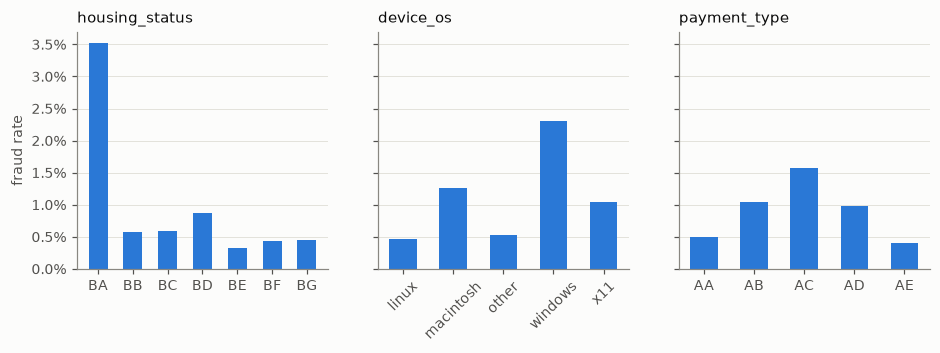

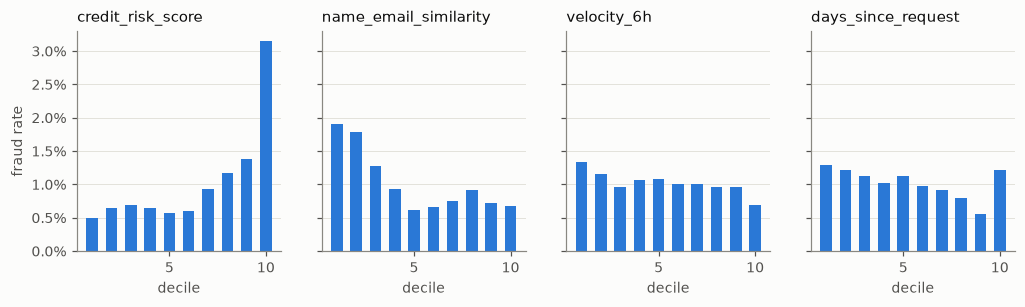

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, field in zip(axes, ["housing_status", "device_os", "payment_type"], strict=True):
    rates = fraud_rate(months_0_5, field)
    ax.bar(rates.index, rates["rate"], width=0.55, color=BLUE)
    ax.set_title(field)
    ax.tick_params(axis="x", labelrotation=45 if field == "device_os" else 0)
    percent_axis(ax)
axes[0].set_ylabel("fraud rate")
plt.show()

numeric = ["credit_risk_score", "name_email_similarity", "velocity_6h", "days_since_request"]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6), sharey=True)
for ax, field in zip(axes, numeric, strict=True):
    deciles = pd.qcut(months_0_5[field], 10, labels=False, duplicates="drop")
    rates = months_0_5.groupby(deciles)["fraud"].mean()
    ax.bar(rates.index + 1, rates.values, width=0.6, color=BLUE)
    ax.set_title(field)
    ax.set_xlabel("decile")
    percent_axis(ax)
axes[0].set_ylabel("fraud rate")
plt.show()

summary = pd.concat({field: fraud_rate(months_0_5, field) for field in CATEGORIES})
summary.style.format({"rate": "{:.2%}", "applications": "{:,}"})

**Decision.** Some single fields separate risk strongly (housing status `BA`, Windows
devices, the top `credit_risk_score` decile), but most relationships are non-linear and
interact: `credit_risk_score` is flat for its lower half and climbs only at the top. A
single-field rule on `credit_risk_score` is kept as the floor every model must beat (the
**baseline rule**, #7), and a **gradient-boosted tree model (LightGBM)** is the served
model because it captures thresholds and interactions that a linear model misses. The
fixed category lists come from these tables.

## 5. Drift across Months

The only section that looks at the Test Months (6–7).

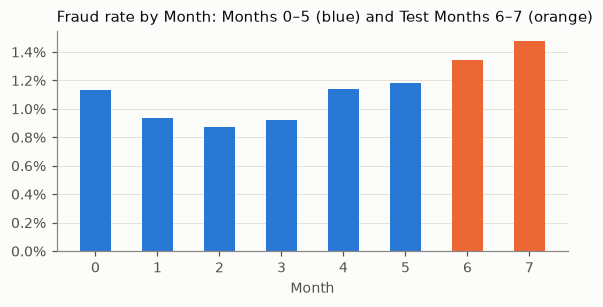

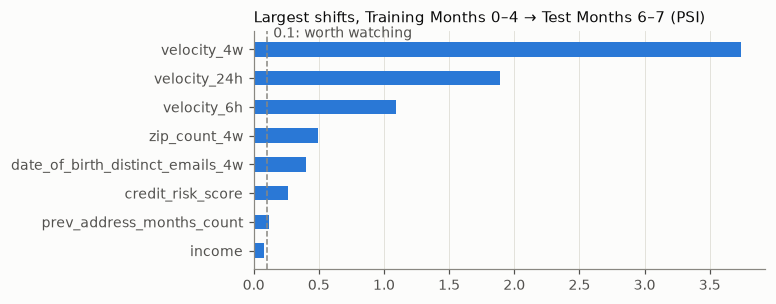

,PSI
velocity_4w,3.739
velocity_24h,1.892
velocity_6h,1.089
zip_count_4w,0.491
date_of_birth_distinct_emails_4w,0.399
credit_risk_score,0.261
prev_address_months_count,0.117
income,0.079
proposed_credit_limit,0.071
session_length_in_minutes,0.063


In [6]:
by_month = fraud_rate(everything, "month")
fig, ax = plt.subplots(figsize=(6, 2.6))
colors = [BLUE if month <= 5 else ORANGE for month in by_month.index]
ax.bar(by_month.index, by_month["rate"], width=0.5, color=colors)
ax.set_title("Fraud rate by Month: Months 0–5 (blue) and Test Months 6–7 (orange)")
ax.set_xlabel("Month")
percent_axis(ax)
plt.show()


def psi(expected, actual, bins=10):
    # Population stability index of actual against expected, on expected's deciles.
    expected, actual = expected.dropna(), actual.dropna()
    edges = np.unique(np.quantile(expected, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    e = np.histogram(np.clip(expected, edges[0], edges[-1]), edges)[0] / len(expected)
    a = np.histogram(np.clip(actual, edges[0], edges[-1]), edges)[0] / len(actual)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(np.sum((a - e) * np.log(a / e)))


numeric_fields = [f for f in FIELDS if f not in CATEGORIES]
training = everything[everything["month"] <= 4]
test = everything[everything["month"] >= 6]
drift = pd.Series({f: psi(training[f], test[f]) for f in numeric_fields}).sort_values(ascending=False)
top = drift.head(8)[::-1]

fig, ax = plt.subplots(figsize=(6, 2.8))
ax.barh(top.index, top.values, height=0.5, color=BLUE)
ax.axvline(0.1, color=MUTED, linewidth=1, linestyle="--")
ax.text(0.15, len(top) - 0.45, "0.1: worth watching", color=INK_2, va="center")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_title("Largest shifts, Training Months 0–4 → Test Months 6–7 (PSI)")
plt.show()
drift.to_frame("PSI").head(10).style.format("{:.3f}")

**Decision.** The fraud rate rises in the Test Months, and several features shift in
distribution, most of all the application-velocity counts (`velocity_4w`, `velocity_24h`,
`velocity_6h`), which move far past the usual 0.1 warning level. A random split would hide this; the **out-of-time split of ADR 0001**
measures it. It also explains why the Threshold chosen on Month 5 flags more than 5% of
Legitimate Applications in Months 6–7: the README reports that actual FPR next to
Recall@5%FPR rather than re-fitting the Threshold on the Test Months.

## 6. Age and fairness

fraud rate aged 50 or over: 2.21%, under 50: 0.75%


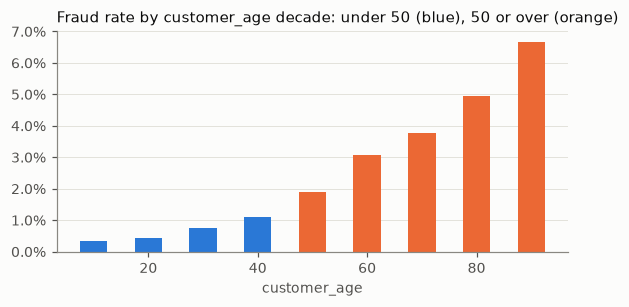

,rate,applications
customer_age,,
10,0.33%,"15,891"
20,0.45%,"199,514"
30,0.76%,"248,111"
40,1.12%,"182,239"
50,1.90%,"114,677"
60,3.08%,"28,306"
70,3.77%,"5,178"
80,4.94%,"1,013"
90,6.67%,60


In [7]:
by_age = fraud_rate(months_0_5, "customer_age")
older = months_0_5["customer_age"] >= 50
print(f"fraud rate aged 50 or over: {months_0_5.loc[older, 'fraud'].mean():.2%}, "
      f"under 50: {months_0_5.loc[~older, 'fraud'].mean():.2%}")

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(by_age.index, by_age["rate"], width=5, color=[ORANGE if a >= 50 else BLUE for a in by_age.index])
ax.set_title("Fraud rate by customer_age decade: under 50 (blue), 50 or over (orange)")
ax.set_xlabel("customer_age")
percent_axis(ax)
plt.show()
by_age.style.format({"rate": "{:.2%}", "applications": "{:,}"})

**Decision.** Fraud rises steadily with age: Applicants aged 50 or over are about three
times as likely to submit a Fraudulent Application. A model that uses age, or anything
correlated with it, will flag older Applicants' Legitimate Applications more often. The
project keeps `customer_age` as a feature and **reports the FPR Ratio between the two Age
Groups** next to every Recall@5%FPR, instead of hiding the disparity (**ADR 0003**).

## 7. Proxies for age

How much of age could a model recover from the other fields? Spearman correlation for
numeric fields; for categories, the correlation ratio (how much of age's variance the
category explains, square-rooted).

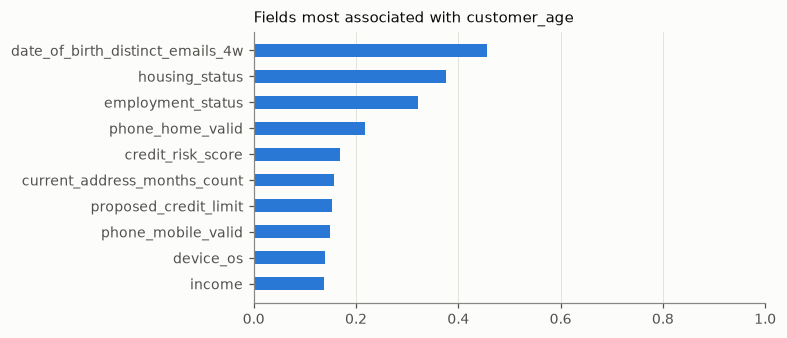

,association with age
date_of_birth_distinct_emails_4w,0.46
housing_status,0.38
employment_status,0.32
phone_home_valid,0.22
credit_risk_score,0.17
current_address_months_count,0.16
proposed_credit_limit,0.15
phone_mobile_valid,0.15
device_os,0.14
income,0.14


In [8]:
def correlation_ratio(categories, values):
    groups = values.groupby(categories, observed=True)
    between = (groups.size() * (groups.mean() - values.mean()) ** 2).sum()
    return float(np.sqrt(between / ((values - values.mean()) ** 2).sum()))


age = months_0_5["customer_age"]
association = {
    field: abs(months_0_5[field].corr(age, method="spearman"))
    for field in FIELDS if field not in CATEGORIES and field != "customer_age"
} | {field: correlation_ratio(months_0_5[field], age) for field in CATEGORIES}
association = pd.Series(association).sort_values(ascending=False)
top = association.head(10)[::-1]

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.barh(top.index, top.values, height=0.5, color=BLUE)
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 1)
ax.set_title("Fields most associated with customer_age")
plt.show()
association.to_frame("association with age").head(10).style.format("{:.2f}")

**Decision.** Several fields carry part of the age signal (most of all
`date_of_birth_distinct_emails_4w`, `housing_status` and `employment_status`), so dropping `customer_age` would not remove the
disparity: the model would partly rebuild age from its proxies while losing recall.
That is why **ADR 0003** rejects "fairness through unawareness", and why comparing the
model with and without age is a follow-up experiment rather than the default.